# E203 — Allocating encoder plasticity under changing distributions

Does selecting which transformer blocks adapt offer useful choices beyond intermittent full training? This is a staged development study. It does not assume a controller is needed.


**COMPLETE · Layer-action identification complete; oracle evidence ready, no controller fitted** — 0/0 minibatches.  
Updated: 2026-11-19T15:00:07.361781+01:00. Worker PID 1980.  
**Conditional whole-run ETA: 2026-11-19T15:00:07.361781+01:00** (Stockholm).  
New A trajectories: 21/21; B: 24/24; C: 144/144.  
Conditional A+B+C estimate; includes monitoring and selected external probes. Full-arm estimates remain until each trajectory completes; stage gates may stop the run.



## What each stage establishes

**A — Actual compute frontier.** Rerun continuous Late4, Late8 and Full on the original walk (three seeds) with deterministic kernels. Add full-model updates paced against the measured per-seed Late4/Late8 training-time budget. Off minibatches skip the heads too. Timing changes the spacing, never the LR or data choice. Report achieved update fractions and runtime mismatch; do not infer savings from update counts. Aggressive→periodic and aggressive→freeze switch at minibatch212, fixed from prior unlabeled development. A preflight found small CUDA nondeterministic update differences despite identical loss and RNG. Deterministic kernels eliminate them in a full-state roundtrip check. Earlier continuous runs are context only; new comparisons use the same numerical setting across all arms.

**B — Repeated shifts.** Pixel-statistic PCA groups A/B/C/D; stream A–B–A–C–B–D–A, 96 minibatches/group. Every return uses distinct images. Regime banks are held out by clip prefix and used only for evaluation. The inherited BDD cohort and its original reservations remain; the new group assignment does not use attribute labels.

**C — Is there adaptive value?** Twelve predeclared Late8 states (four stages × three seeds), four layer actions, three fresh paired augmentation draws:144 branches. Readouts at0/8/16/32, no appended continuation. Heads adapt for Late4/Late8/Full; Complete Skip freezes everything. Early stem+blocks1–4, middle blocks5–8, late blocks9–12+final norm. Same optimizer groups and0.75 layer decay for every enabled parameter.

**Setting-validity gates:** A requires ≤5% measured cost mismatch on each seed; B requires a frozen-feature between-regime MMD above its within-regime split null, and a noncollapsed Late8 source. Passing these gates does not establish adaptive advantage. The independent-draw oracle is the test of that claim.

**Outcomes:** LiDAR, continuous retrieval margin, historical neighborhoods, centered and uncentered rank, normalized dispersion and layer-wise CKA. Larger LiDAR/rank is not automatically better semantic utility. Time averages use trapezoidal integration on the registered readout grid, not endpoint-only scores. Training/decode, monitoring, external probes and wall time are reported separately.

**External diagnostics:** scene, weather, lighting, traffic-light and pedestrian balanced accuracy (fixed linear and kNN protocol). At states104 and200, all actions/draws receive terminal probes (72 outcomes). Labels never enter features, thresholds, schedule selection or deployed actions. A semantic oracle is an offline diagnostic only.

**Oracle analysis:** choose an action on two draws, evaluate on the third; compare with Skip, fixed Full and the best fixed action selected on the other two seeds. Report selection frequencies, action gaps, draw agreement and seed-level paired differences. Three seeds give limited precision. No predictor is fitted automatically.

**Features saved for a later ridge study:** per-layer rank, retrieval, CKA, novelty, RBF MMD², gradient norms, actual AdamW trial-update magnitude, history and incoming redundancy. Reference samples for these features are past observations or the pre-existing monitor bank, never a future regime bank.

**Resuming:** one rolling full model/optimizer/AMP checkpoint. Finished arms and branches are immutable JSON. No branch-model archive. New results are development evidence; reserved confirmation seeds remain untouched.


## Phase A — completed trajectories

| Seed | Policy | Encoder updates | Train+decode min | Health min | External min | Wall min | Mean LiDAR | Mean margin | Cost error |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| 1 | aggressive-freeze | 212 | 1.90 | 0.89 | 0.42 | 4.82 | 57.611 | 0.03925 | — |
| 1 | aggressive-periodic | 583 | 5.28 | 0.88 | 0.42 | 7.68 | 58.248 | 0.03670 | — |
| 1 | full-cost-late4 | 932 | 8.62 | 0.91 | 0.41 | 11.12 | 60.991 | 0.04560 | -0.0% |
| 1 | full-cost-late8 | 1339 | 12.07 | 0.89 | 0.41 | 14.46 | 60.417 | 0.04178 | 0.0% |
| 1 | full | 1693 | 15.57 | 0.92 | 0.42 | 18.03 | 61.866 | 0.04223 | — |
| 1 | late4 | 1693 | 8.62 | 0.96 | 0.42 | 10.85 | 65.989 | 0.05114 | — |
| 1 | late8 | 1693 | 12.07 | 0.94 | 0.42 | 14.35 | 62.434 | 0.04192 | — |
| 2 | aggressive-freeze | 212 | 1.89 | 0.89 | 0.42 | 4.76 | 59.518 | 0.04477 | — |
| 2 | aggressive-periodic | 583 | 5.26 | 0.87 | 0.42 | 7.63 | 60.037 | 0.04136 | — |
| 2 | full-cost-late4 | 909 | 8.33 | 0.90 | 0.41 | 10.72 | 60.650 | 0.04335 | -0.0% |
| 2 | full-cost-late8 | 1208 | 11.86 | 0.98 | 0.47 | 14.42 | 59.552 | 0.04355 | -0.0% |
| 2 | full | 1693 | 15.27 | 0.89 | 0.42 | 17.65 | 60.625 | 0.03687 | — |
| 2 | late4 | 1693 | 8.33 | 0.93 | 0.43 | 10.35 | 64.792 | 0.04925 | — |
| 2 | late8 | 1693 | 11.87 | 0.92 | 0.42 | 14.04 | 63.186 | 0.04495 | — |
| 3 | aggressive-freeze | 212 | 1.90 | 0.89 | 0.41 | 4.69 | 59.740 | 0.03585 | — |
| 3 | aggressive-periodic | 583 | 5.30 | 0.88 | 0.42 | 7.71 | 60.382 | 0.03301 | — |
| 3 | full-cost-late4 | 903 | 8.36 | 0.92 | 0.42 | 10.77 | 63.029 | 0.04407 | -0.0% |
| 3 | full-cost-late8 | 1332 | 11.82 | 0.87 | 0.41 | 14.09 | 62.458 | 0.04332 | -0.0% |
| 3 | full | 1693 | 15.41 | 0.90 | 0.42 | 17.77 | 61.629 | 0.03784 | — |
| 3 | late4 | 1693 | 8.36 | 0.92 | 0.43 | 10.38 | 65.118 | 0.05032 | — |
| 3 | late8 | 1693 | 11.83 | 0.93 | 0.43 | 14.00 | 64.708 | 0.03926 | — |

## Phase B — completed trajectories

| Seed | Policy | Encoder updates | Train+decode min | Health min | External min | Wall min | Mean LiDAR | Mean margin | Cost error |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| 1 | aggressive-freeze | 212 | 1.95 | 3.76 | 0.47 | 6.88 | 59.947 | 0.03628 | — |
| 1 | aggressive-periodic | 327 | 3.00 | 3.70 | 0.48 | 7.88 | 60.101 | 0.03471 | — |
| 1 | full-cost-late4 | 379 | 3.42 | 3.69 | 0.47 | 8.22 | 63.263 | 0.04205 | -0.1% |
| 1 | full-cost-late8 | 521 | 4.79 | 3.69 | 0.47 | 9.62 | 62.646 | 0.04285 | -0.0% |
| 1 | full | 672 | 6.07 | 3.71 | 0.47 | 10.87 | 62.935 | 0.04152 | — |
| 1 | late4 | 672 | 3.39 | 3.85 | 0.50 | 8.28 | 67.342 | 0.04537 | — |
| 1 | late8 | 672 | 4.76 | 3.81 | 0.49 | 9.66 | 65.296 | 0.04334 | — |
| 1 | skip | 0 | 0.00 | 3.95 | 0.51 | 4.95 | 66.323 | 0.03830 | — |
| 2 | aggressive-freeze | 212 | 1.91 | 3.73 | 0.48 | 6.97 | 61.466 | 0.03906 | — |
| 2 | aggressive-periodic | 327 | 3.00 | 3.71 | 0.47 | 7.98 | 61.352 | 0.03819 | — |
| 2 | full-cost-late4 | 352 | 3.30 | 3.80 | 0.46 | 8.61 | 63.780 | 0.04010 | -0.1% |
| 2 | full-cost-late8 | 507 | 4.71 | 3.76 | 0.47 | 9.80 | 63.680 | 0.04207 | -0.0% |
| 2 | full | 672 | 6.27 | 3.83 | 0.48 | 11.41 | 62.498 | 0.03975 | — |
| 2 | late4 | 672 | 3.38 | 3.83 | 0.49 | 8.27 | 66.081 | 0.04255 | — |
| 2 | late8 | 672 | 4.81 | 3.97 | 0.49 | 9.90 | 65.858 | 0.04078 | — |
| 2 | skip | 0 | 0.00 | 3.93 | 0.51 | 4.94 | 66.323 | 0.03830 | — |
| 3 | aggressive-freeze | 212 | 1.78 | 3.55 | 0.45 | 6.48 | 60.170 | 0.04435 | — |
| 3 | aggressive-periodic | 327 | 2.90 | 3.56 | 0.46 | 7.68 | 60.478 | 0.04359 | — |
| 3 | full-cost-late4 | 362 | 3.32 | 3.69 | 0.47 | 8.27 | 63.152 | 0.04117 | -0.0% |
| 3 | full-cost-late8 | 514 | 4.70 | 3.74 | 0.47 | 9.69 | 61.633 | 0.04339 | 0.0% |
| 3 | full | 672 | 6.08 | 3.67 | 0.47 | 11.04 | 62.314 | 0.04130 | — |
| 3 | late4 | 672 | 3.38 | 3.85 | 0.50 | 8.29 | 65.413 | 0.04480 | — |
| 3 | late8 | 672 | 4.67 | 3.75 | 0.48 | 9.54 | 63.133 | 0.04248 | — |
| 3 | skip | 0 | 0.00 | 3.97 | 0.51 | 4.99 | 66.323 | 0.03830 | — |

## Paired Reproduction

```json
{
  "passed": true,
  "replicates": 2,
  "identical_rng": 203010001,
  "losses": [
    -0.8432979583740234,
    -0.8432979583740234
  ],
  "complete_payload_hashes": [
    "8095c8136f8530a87b71a6ba7d826a9d036f5a10e2e0a56c83e30e9b8f8cde40",
    "8095c8136f8530a87b71a6ba7d826a9d036f5a10e2e0a56c83e30e9b8f8cde40"
  ],
  "source_immutable": true,
  "scope": "One real Full update repeated from identical full model, BN buffers, optimizer and AMP; exact tensor equality."
}
```


## Gate A

```json
{
  "passed": true,
  "compute_matches": [
    {
      "seed": 1,
      "arm": "full-cost-late4",
      "relative_runtime_error": -0.00046112618510329995,
      "encoder_update_fraction": 0.5505020673360898
    },
    {
      "seed": 1,
      "arm": "full-cost-late8",
      "relative_runtime_error": 0.00018083099551335913,
      "encoder_update_fraction": 0.7909037212049616
    },
    {
      "seed": 2,
      "arm": "full-cost-late4",
      "relative_runtime_error": -4.314556197859698e-05,
      "encoder_update_fraction": 0.5369167158889545
    },
    {
      "seed": 2,
      "arm": "full-cost-late8",
      "relative_runtime_error": -0.00020802347036763535,
      "encoder_update_fraction": 0.713526284701713
    },
    {
      "seed": 3,
      "arm": "full-cost-late4",
      "relative_runtime_error": -0.0002750179302853928,
      "encoder_update_fraction": 0.5333727111636148
    },
    {
      "seed": 3,
      "arm": "full-cost-late8",
      "relative_runtime_error": -0.00031286745212844025,
      "encoder_update_fraction": 0.7867690490253987
    }
  ],
  "finite_health": true,
  "caveat": "Runtime-credit cadence is hardware/timing-dependent. Source historical runtimes are the fixed targets; timing-driven update indices are saved. This does not guarantee equal FLOPs.",
  "next": "Repeated-shift setting, not a controller search."
}
```


## Gate B

```json
{
  "passed": true,
  "between_mmd2": [
    0.10296092751945252,
    0.31891554608933903,
    0.32551829491349704,
    0.16846732909180906,
    0.1738217658021337,
    0.02373301053952237
  ],
  "within_split_mmd2": [
    0.01936856774863349,
    0.025207586182071973,
    0.02844116299787247,
    0.021326072613470082
  ],
  "visually_distinct_in_frozen_features": true,
  "source_health_ratios": [
    {
      "seed": 1,
      "centered_rank": 0.8393331698495196,
      "dispersion": 1.0
    },
    {
      "seed": 2,
      "centered_rank": 0.8493974901782066,
      "dispersion": 1.0
    },
    {
      "seed": 3,
      "centered_rank": 0.8345334708309038,
      "dispersion": 1.0
    }
  ],
  "setting_only": "This gate checks a measurable shift and viable source, not whether adaptive control has value.",
  "action_opportunity": "Evaluated next with paired branches; no predictor or MPC yet."
}
```


## Independent-draw diagnostic oracles

| Selection target | States | Winner agreement | Mean action range | Gain vs Skip | Gain vs Full | Gain vs cross-seed fixed | Seed bootstrap95 |
| --- | --- | --- | --- | --- | --- | --- | --- |
| lidar | 12 | 83.3% | 0.75641 | +0.15581 | +0.57389 | +0.15581 | [0.10977542466484813, 0.19904532928133514] |
| margin | 12 | 61.1% | 0.00066 | +0.00053 | +0.00025 | +0.00007 | [-2.0242723015447457e-05, 0.00020933713919172683] |
| current_margin | 12 | 75.0% | 0.00091 | +0.00079 | +0.00040 | +0.00004 | [-2.6391857924560707e-05, 0.0001581303852920731] |
| semantic | 6 | 66.7% | 0.00438 | +0.00178 | +0.00204 | +0.00311 | [0.002367842562254955, 0.0037544195295704887] |

Independent-draw evidence, not deployment. Positive same-draw maxima alone do not establish control value. Compare independent gains with best cross-seed fixed action; only three source seeds. No predictor fitted. Full fold-level results: C:\CAFL-E\analysis\2026-11-09-one-step-mpc\o3-simsiam-control\e203\oracle-summary.json


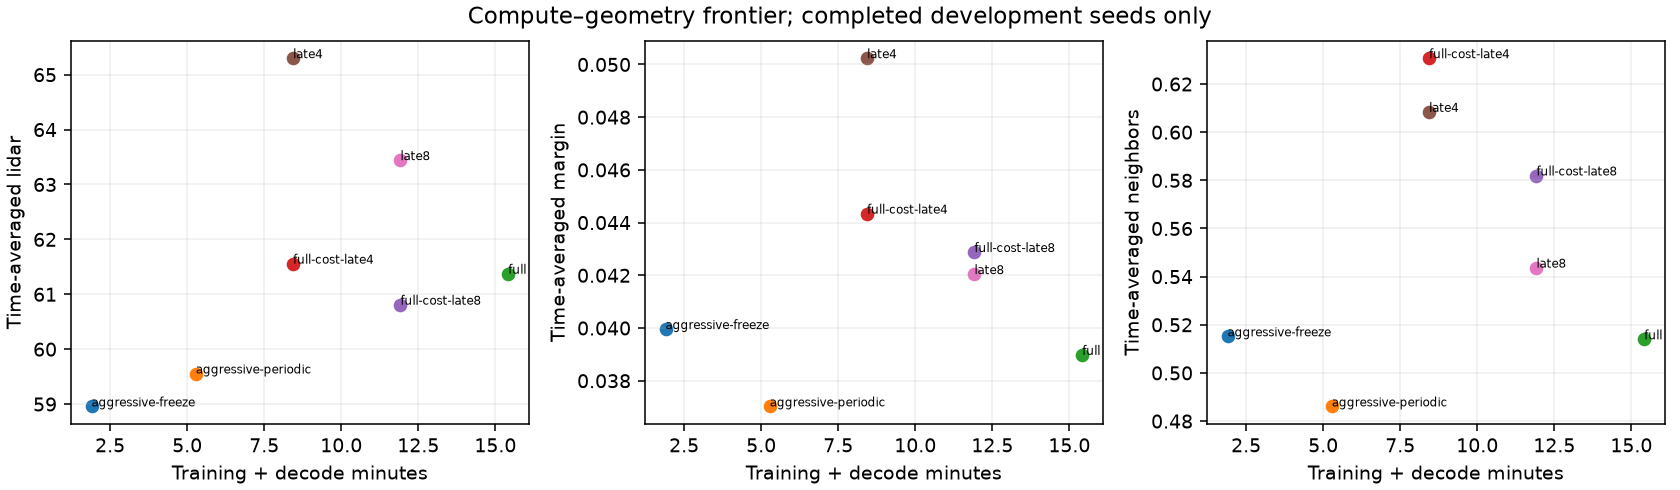

In [ ]:
from IPython.display import Image, display
display(Image(filename='C:\\CAFL-E\\analysis\\2026-11-09-one-step-mpc\\o3-simsiam-control\\e203\\frontier-a.png'))

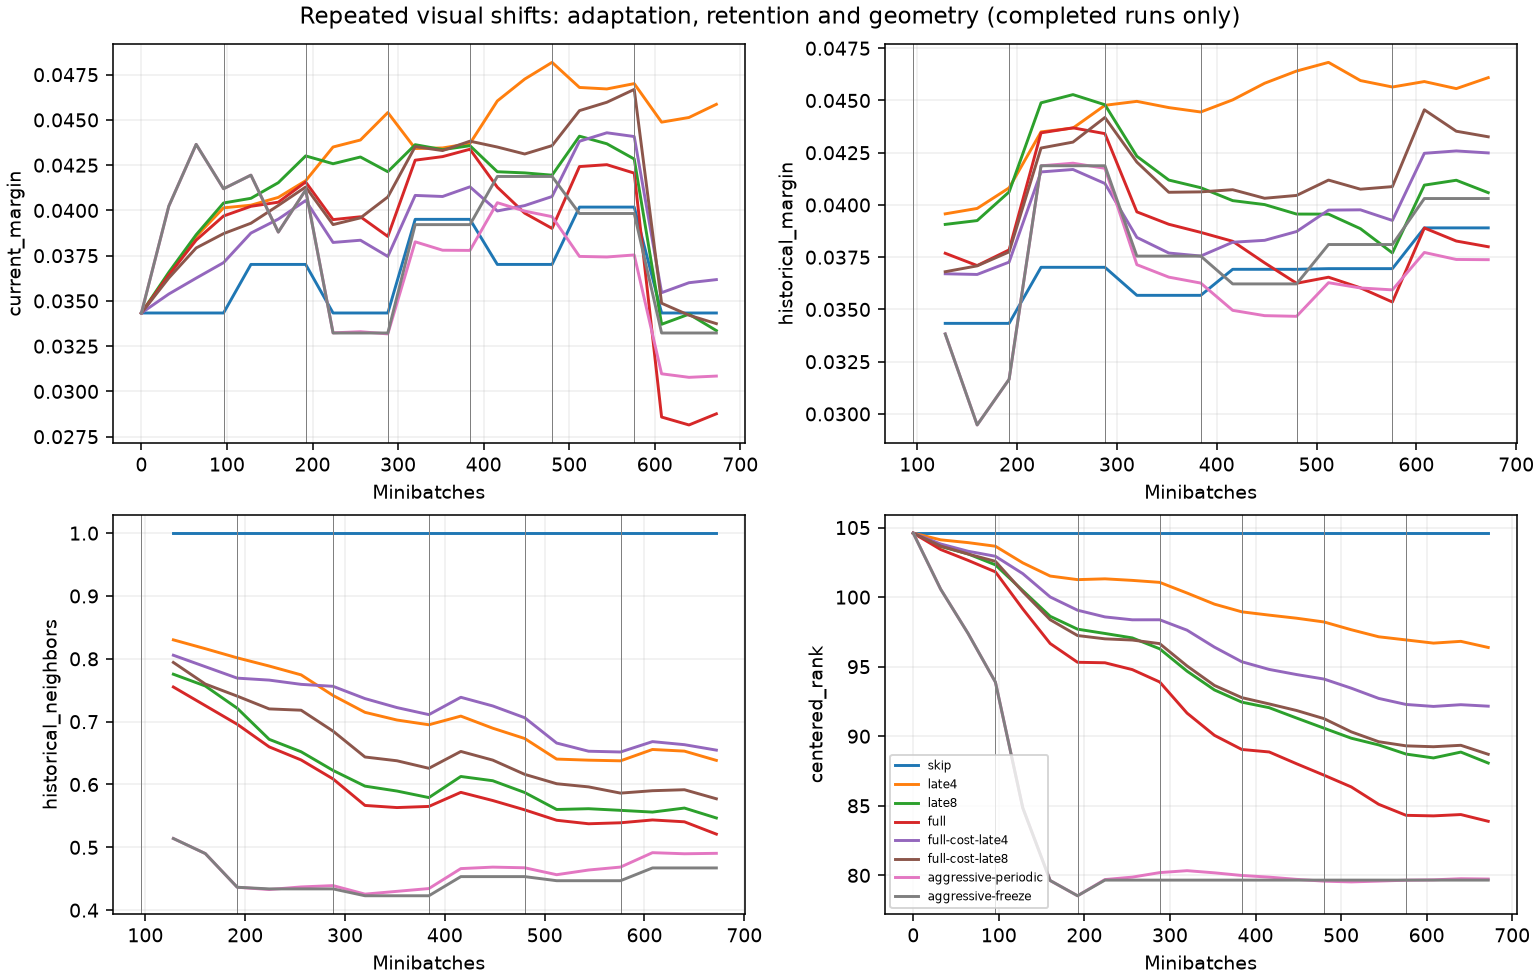

In [ ]:
from IPython.display import Image, display
display(Image(filename='C:\\CAFL-E\\analysis\\2026-11-09-one-step-mpc\\o3-simsiam-control\\e203\\trajectory-b.png'))